In [1]:
# 11.0 — Rutas, GPU y reproducibilidad
import os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

def arbol(ruta, nivel=0, max_nivel=4, max_items=6):
    items = sorted(os.listdir(ruta))
    for nombre in items[:max_items]:
        p = os.path.join(ruta, nombre)
        print("    " * nivel + ("📁 " if os.path.isdir(p) else "📄 ") + nombre)
        if os.path.isdir(p) and nivel + 1 < max_nivel and nombre != "npy":
            arbol(p, nivel + 1, max_nivel, max_items)
    if len(items) > max_items:
        print("    " * nivel + f"... (+{len(items) - max_items} más)")

arbol("/kaggle/input")

SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
fijar_semilla()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nPyTorch:", torch.__version__, "| dispositivo:", DEVICE,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "SIN GPU")


📁 notebooks
    📁 bryansalva
        📁 03-cortes
            📄 __notebook__.ipynb
            📄 __output__.json
            📄 __results__.html
            📁 __results___files
            📄 custom.css
            📄 indice_npy.csv
            ... (+2 más)

PyTorch: 2.11.0+cu128 | dispositivo: cuda | Tesla T4


In [8]:
# 11.1 — Índice: positivos, inciertos (−1) y desbalance por split
NB03 = Path("/kaggle/input/notebooks/bryansalva/03-cortes")
OUT  = Path("/kaggle/working")
LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]

indice = pd.read_csv(NB03 / "indice_npy.csv")
assert len(list((NB03 / "npy").glob("*.npy"))) == len(indice) == 656
print("Estudios:", indice["split"].value_counts().to_dict())

def resumen(df):
    return pd.DataFrame({"pos": (df[LABELS] == 1).sum(), "−1": (df[LABELS] == -1).sum(),
                         "%pos": ((df[LABELS] == 1).mean() * 100).round(1)})

tabla = pd.concat({s: resumen(indice[indice.split == s]) for s in ["train", "val", "test"]}, axis=1)
tr = indice[indice.split == "train"]
tabla[("train", "neg/pos")] = ((tr[LABELS] == 0).sum() / (tr[LABELS] == 1).sum()).round(1)
print(tabla.to_string())


Estudios: {'train': 480, 'val': 120, 'test': 56}
                 train           val           test            train
                   pos  −1  %pos pos  −1  %pos  pos −1  %pos neg/pos
ACL                 96  28  20.0  24   8  20.0   23  0  41.1     3.7
MCL                 69  40  14.4  17  11  14.2    9  0  16.1     5.4
Medial Meniscus    190  18  39.6  48   8  40.0   24  0  42.9     1.4
Lateral Meniscus    92  16  19.2  23   4  19.2   23  0  41.1     4.0
Medial OA          110  51  22.9  28  12  23.3   15  0  26.8     2.9
Lateral OA          93  42  19.4  23  13  19.2   11  0  19.6     3.7
PF OA              112  95  23.3  28  25  23.3   20  0  35.7     2.4
Effusion           209  97  43.5  52  32  43.3   34  0  60.7     0.8
Synovitis           87   2  18.1  22   0  18.3   25  0  44.6     4.5
Baker's            109   1  22.7  27   0  22.5   11  0  19.6     3.4
Contusion           76  65  15.8  19   8  15.8   18  0  32.1     4.5
Fracture            70   8  14.6  18   2  15.0   17  0

###  — Positivos, inciertos y desbalance

**train y val son casi idénticos** en % de positivos (p. ej. ACL 20.0 / 20.0, Effusion 43.5 / 43.3) → la
estratificación del Paso 9 funcionó: val es una buena muestra de train para elegir épocas y umbrales.

**El test (gold) está mucho más enriquecido** que train:
| Hallazgo | train | test |
|---|---|---|
| Synovitis | 18 % | **45 %** |
| ACL | 20 % | **41 %** |
| Lateral Meniscus | 19 % | **41 %** |
| Contusion | 16 % | **32 %** |
| Fracture | 15 % | **30 %** |
| Effusion | 44 % | **61 %** |

- El **AUC no depende de la prevalencia** (mide si los positivos quedan por encima de los negativos) → sigue siendo
  comparable entre val y test; por eso es la métrica oficial.
- **Precision y F1 sí dependen de la prevalencia** → un umbral elegido en val puede no transferir al test (declararlo).

**Etiquetas inciertas (−1) en train:** muchas en **Effusion (97), PF OA (95), Contusion (65), Medial OA (51),
Lateral OA (42) y MCL (40)**; casi ninguna en Synovitis (2), Baker's (1) y Fracture (8). La política del −1 cambiará
sobre todo esas 6 etiquetas (p. ej. PF OA pasaría de 112 a 207 positivos con "−1 como 1").

**Desbalance (neg/pos en train):** de **0.8** (Effusion, más positivos que negativos) a **5.7** (Fracture). Es moderado
gracias a la cuota mínima de 60 positivos por etiqueta del Paso 9 (en la población real sería mucho mayor). Mitigación
prevista: `pos_weight = neg/pos` en `BCEWithLogitsLoss` (req. 6).


cargando:   0%|          | 0/656 [00:00<?, ?it/s]

Batch x: (16, 15, 256, 256) | y: (16, 12) | valores y: [-1.0, 0.0, 1.0]


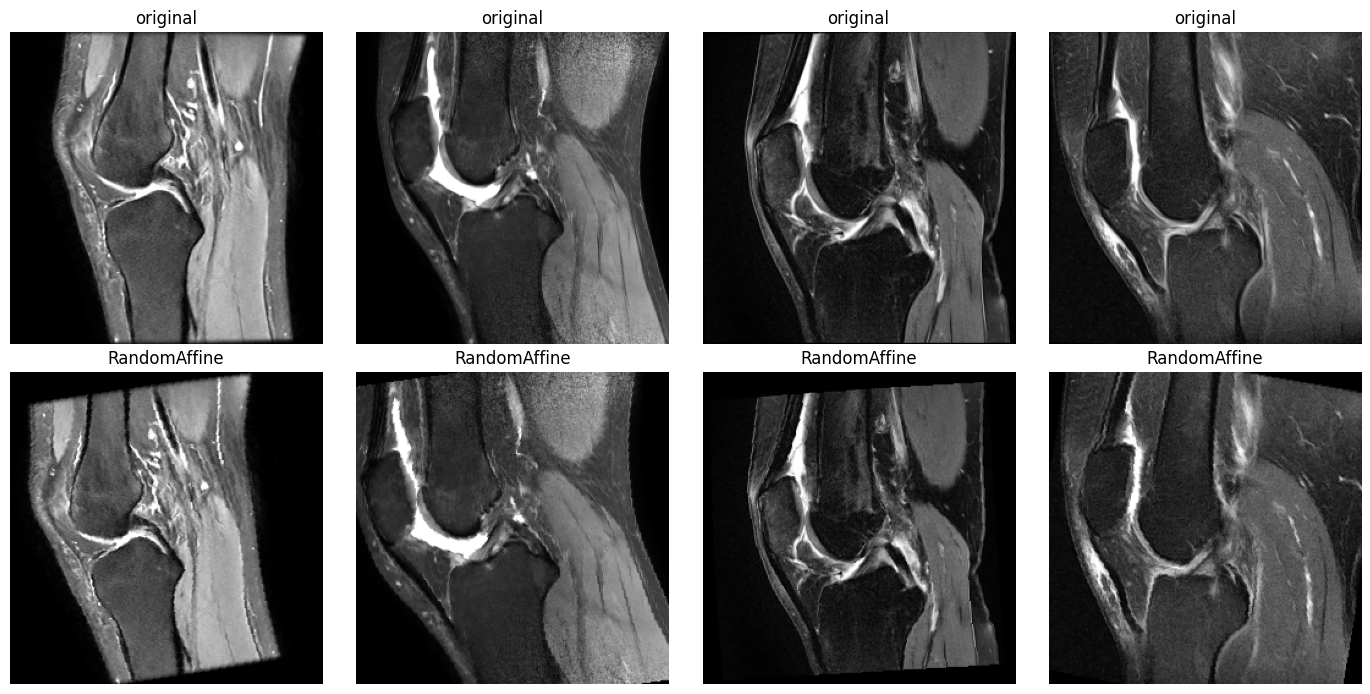

In [9]:
# 11.2 — Dataset de PyTorch + transforms (como en los laboratorios)
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from tqdm.auto import tqdm

VOL = {u: np.load(NB03 / "npy" / f"{u}.npy") for u in tqdm(indice["StudyInstanceUID"], desc="cargando")}

class RodillaDataset(Dataset):
    def __init__(self, df, canales, transform=None):
        self.uids = df["StudyInstanceUID"].tolist()
        self.y = df[LABELS].to_numpy(np.float32)      # 1 / 0 / −1 (el −1 se trata en la pérdida)
        self.canales = canales
        self.transform = transform

    def __len__(self):
        return len(self.uids)

    def __getitem__(self, i):
        x = torch.from_numpy(VOL[self.uids[i]][self.canales].astype(np.float32))
        if self.transform is not None:
            x = self.transform(x)
        return x, torch.from_numpy(self.y[i])

IMAGENET = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # como en el lab de ResNet

def crear_loaders(canales, imagenet=False, batch_size=16):
    aumento = [transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.9, 1.1))]
    norm = [IMAGENET] if imagenet else []
    tfs = {"train": transforms.Compose(aumento + norm),
           "val": transforms.Compose(norm), "test": transforms.Compose(norm)}
    datasets = {s: RodillaDataset(indice[indice.split == s], canales, tfs[s]) for s in ["train", "val", "test"]}
    loaders = {s: DataLoader(datasets[s], batch_size=batch_size, shuffle=(s == "train"), num_workers=2)
               for s in datasets}
    return datasets, loaders

# Para la VGG desde cero: los 15 cortes como canales
ds_vgg, dl_vgg = crear_loaders(canales=list(range(15)))
xb, yb = next(iter(dl_vgg["train"]))
print("Batch x:", tuple(xb.shape), "| y:", tuple(yb.shape), "| valores y:", torch.unique(yb).tolist())

# Original vs aumentado (canal 7, centro)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for c in range(4):
    x0, _ = ds_vgg["val"][c]                                         # val: sin aumento
    ax[0, c].imshow(x0[7], cmap="gray", vmin=0, vmax=1); ax[0, c].set_title("original")
    ax[1, c].imshow(ds_vgg["train"].transform(x0)[7], cmap="gray", vmin=0, vmax=1); ax[1, c].set_title("RandomAffine")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()


In [10]:
# 11.3 — VGG del Laboratorio de la Clase 4, configuración 'A' (VGG-11) con BatchNorm
import torch.nn as nn
import torch.optim as optim
import copy

VGG_CFGS = {
    'A': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],                          # VGG-11
    'D': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],  # VGG-16
}

class VGG(nn.Module):
    """VGGNet configurable (Lab Clase 4), adaptada: 15 canales de entrada, 12 salidas, clasificador reducido."""

    def __init__(self, cfg_name: str, num_classes: int = 12, in_channels: int = 15, batch_norm: bool = True):
        super().__init__()
        self.features = self._make_layers(VGG_CFGS[cfg_name], in_channels, batch_norm)
        self.avgpool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(                       # como VGGCifar del lab (Ejercicio C.2)
            nn.Linear(512 * 4 * 4, 512), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )

    @staticmethod
    def _make_layers(cfg, in_channels, batch_norm):
        layers = []
        for v in cfg:
            if v == 'M':
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
            else:
                layers += [nn.Conv2d(in_channels, v, kernel_size=3, padding=1)]
                if batch_norm:
                    layers += [nn.BatchNorm2d(v)]
                layers += [nn.ReLU(inplace=True)]
                in_channels = v
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x                                                # logits (sin sigmoide)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


fijar_semilla()
vgg11 = VGG('A').to(DEVICE)
print(f"VGG-11 (BN): {count_params(vgg11) / 1e6:.2f} M parámetros "
      f"| features {count_params(vgg11.features) / 1e6:.2f} M | classifier {count_params(vgg11.classifier) / 1e6:.2f} M")
print(f"(VGG-11 original del paper: 133 M, casi todo en las capas FC de 4096)")

with torch.no_grad():
    logits = vgg11(xb.to(DEVICE))
print("Salida:", tuple(logits.shape))
print("Probabilidades iniciales del 1er estudio:", torch.sigmoid(logits[0]).cpu().numpy().round(2))


VGG-11 (BN): 13.43 M parámetros | features 9.23 M | classifier 4.20 M
(VGG-11 original del paper: 133 M, casi todo en las capas FC de 4096)
Salida: (16, 12)
Probabilidades iniciales del 1er estudio: [0.39 0.57 0.57 0.68 0.47 0.38 0.58 0.53 0.45 0.65 0.55 0.36]


### Arquitectura desde cero: VGG-11 con BatchNorm (Laboratorio de la Clase 4)

Se usa la **misma clase `VGG` del laboratorio** (`VGG_CFGS` + `_make_layers` + opción `batch_norm`) con la
**configuración 'A' (VGG-11)** de la Tabla 1 del artículo de Simonyan & Zisserman (2015).

| | Lab (Clase 4) | Nuestra versión | Por qué |
|---|---|---|---|
| Bloques convolucionales | `VGG_CFGS['A']`: conv 3×3 + `'M'` | **Igual** | Es la VGG-11 del paper (Tabla 1) |
| BatchNorm | opción `batch_norm` | **`True`** | Entrenar una VGG desde cero sin BN con pocos datos es muy inestable (el lab ya trae esta opción) |
| Canales de entrada | 3 (RGB) | **15** (cortes) | La imagen 2.5D tiene 15 cortes sagitales, no 3 colores |
| `avgpool` | `(7, 7)` | **`(4, 4)`** | Clasificador más chico |
| Clasificador | 25088 → 4096 → 4096 → 1000 (**~120 M**) | **8192 → 512 → 12** | El mismo esquema reducido de `VGGCifar` del lab (Ejercicio C.2): con 480 estudios, 120 M de parámetros memorizarían todo |
| Salida | `num_classes` + softmax | **12 logits** → sigmoide | Multietiqueta: un estudio puede tener varios hallazgos a la vez (lo exige el examen) |

- Se conserva también la configuración **'D' (VGG-16)** en `VGG_CFGS` para la ablación de **profundidad** (VGG-11 vs VGG-16).
- La red devuelve **logits**: `BCEWithLogitsLoss` aplica la sigmoide por dentro (numéricamente más estable) y las
  probabilidades se obtienen con `torch.sigmoid` solo al evaluar.


### Interpretación 11.3 — VGG-11 (BN) antes de entrenar
- **13.43 M parámetros**: `features` 9.23 M (los 8 bloques conv 3×3 de la configuración 'A', casi iguales a la VGG-11
  original: solo cambia la primera capa, de 3 a 15 canales) + `classifier` 4.20 M.
- Frente a los **133 M** de la VGG-11 original, el modelo es **10 veces más chico**: la diferencia está casi toda en las
  capas FC de 4096 → reducirlas era indispensable para 480 estudios.
- Salida (16, 12) = 12 logits por estudio. Probabilidades iniciales entre 0.36 y 0.68 (≈ 0.5): la red aún no aprendió nada.


In [11]:
# 11.4a — Política del −1, pérdida con pos_weight (desbalance) y AUC por etiqueta
from sklearn.metrics import roc_auc_score

POLITICA = "ignorar"     # "ignorar" (modelo base) | "cero" | "uno"  → factor de la ablación

def objetivo_y_mascara(y, politica):
    """y trae 1 / 0 / −1. Devuelve el objetivo 0/1 y una máscara (1 = cuenta en la pérdida)."""
    if politica == "cero": return y.clamp(min=0), torch.ones_like(y)    # −1 → 0
    if politica == "uno":  return y.abs(), torch.ones_like(y)           # −1 → 1
    return y.clamp(min=0), (y != -1).float()                            # −1 → no cuenta

def pos_weight_de(dataset, politica):
    obj, masc = objetivo_y_mascara(torch.from_numpy(dataset.y), politica)
    return ((1 - obj) * masc).sum(0) / (obj * masc).sum(0)              # negativos / positivos

def auc_por_etiqueta(P, Y):
    """AUC de cada hallazgo usando solo las etiquetas conocidas (0/1): los −1 se excluyen."""
    res = {}
    for j, e in enumerate(LABELS):
        m = Y[:, j] != -1
        res[e] = roc_auc_score(Y[m, j], P[m, j]) if len(np.unique(Y[m, j])) == 2 else np.nan
    return pd.Series(res)

print("pos_weight (neg/pos en train) según la política del −1:")
print(pd.DataFrame({p: pos_weight_de(ds_vgg["train"], p).numpy() for p in ["ignorar", "cero", "uno"]},
                   index=LABELS).round(2))


pos_weight (neg/pos en train) según la política del −1:
                  ignorar  cero   uno
ACL                  3.71  4.00  2.87
MCL                  5.38  5.96  3.40
Medial Meniscus      1.43  1.53  1.31
Lateral Meniscus     4.04  4.22  3.44
Medial OA            2.90  3.36  1.98
Lateral OA           3.71  4.16  2.56
PF OA                2.44  3.29  1.32
Effusion             0.83  1.30  0.57
Synovitis            4.49  4.52  4.39
Baker's              3.39  3.40  3.36
Contusion            4.46  5.32  2.40
Fracture             5.74  5.86  5.15


Época  1/60 | pérdida train 1.092 | pérdida val 1.051 | AUC val 0.597 ★ | lr 1e-02
Época  2/60 | pérdida train 1.028 | pérdida val 1.025 | AUC val 0.624 ★ | lr 1e-02
Época  3/60 | pérdida train 1.017 | pérdida val 1.032 | AUC val 0.624 ★ | lr 1e-02
Época  4/60 | pérdida train 0.999 | pérdida val 1.024 | AUC val 0.648 ★ | lr 1e-02
Época  5/60 | pérdida train 0.996 | pérdida val 1.042 | AUC val 0.641 | lr 1e-02
Época  6/60 | pérdida train 0.994 | pérdida val 1.033 | AUC val 0.658 ★ | lr 1e-02
Época  7/60 | pérdida train 0.992 | pérdida val 1.005 | AUC val 0.669 ★ | lr 1e-02
Época  8/60 | pérdida train 0.975 | pérdida val 1.041 | AUC val 0.661 | lr 1e-02
Época  9/60 | pérdida train 0.980 | pérdida val 1.028 | AUC val 0.611 | lr 1e-02
Época 10/60 | pérdida train 0.965 | pérdida val 1.022 | AUC val 0.647 | lr 1e-02
Época 11/60 | pérdida train 0.967 | pérdida val 0.996 | AUC val 0.688 ★ | lr 1e-02
Época 12/60 | pérdida train 0.966 | pérdida val 1.009 | AUC val 0.659 | lr 1e-02
Época 13/60 | 

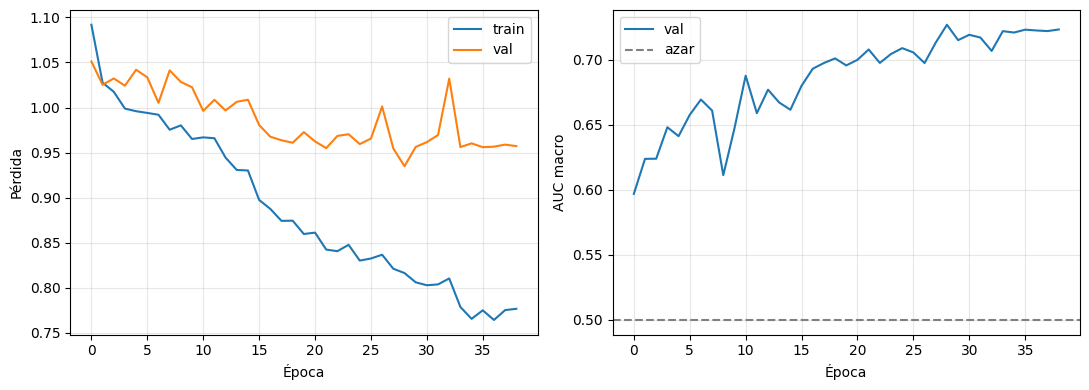

Lateral Meniscus    0.621
Baker's             0.632
Medial Meniscus     0.662
Lateral OA          0.690
Fracture            0.699
MCL                 0.703
ACL                 0.729
PF OA               0.732
Contusion           0.770
Synovitis           0.779
Medial OA           0.835
Effusion            0.870


In [15]:
# 11.4b — Entrenamiento al estilo del Lab de la Clase 5 (SGD + momentum, fases train/val, deepcopy del mejor)
def train_model(model, loaders, datasets, epochs=30, lr=0.01, weight_decay=5e-4, politica=POLITICA):
    model.to(DEVICE)
    pos_weight = pos_weight_de(datasets["train"], politica).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight, reduction="none")
    # Solo se pasan al optimizador los parámetros con requires_grad=True (igual que en el lab)
    optimizer = optim.SGD(filter(lambda p: p.requires_grad, model.parameters()),
                          lr=lr, momentum=0.9, weight_decay=weight_decay)
    
    # Como en el artículo de VGG (Sec. 3.1): lr ÷ 10 cuando el AUC de val deja de mejorar
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.1, patience=3)


    history = {"train_loss": [], "val_loss": [], "val_auc": []}

    best_auc, best_wts, best_tabla = 0.0, copy.deepcopy(model.state_dict()), None
    sin_mejora = 0

    t_start = time.time()

    for epoch in range(epochs):
        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()
            running_loss, n, P, Y = 0.0, 0, [], []
            for inputs, labels in loaders[phase]:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)                                   # logits
                    target, mask = objetivo_y_mascara(labels, politica)
                    loss = (criterion(outputs, target) * mask).sum() / mask.sum()
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                n += inputs.size(0)
                if phase == "val":
                    P.append(torch.sigmoid(outputs).cpu()); Y.append(labels.cpu())
            history[f"{phase}_loss"].append(running_loss / n)

        auc = auc_por_etiqueta(torch.cat(P).numpy(), torch.cat(Y).numpy())
        history["val_auc"].append(auc.mean())
        scheduler.step(auc.mean())
        marca = ""
        if auc.mean() > best_auc:
            best_auc, best_tabla, marca = auc.mean(), auc, " ★"
            best_wts = copy.deepcopy(model.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1

        print(f"Época {epoch + 1:2d}/{epochs} | pérdida train {history['train_loss'][-1]:.3f} | "
            f"pérdida val {history['val_loss'][-1]:.3f} | AUC val {auc.mean():.3f}{marca} | lr {optimizer.param_groups[0]['lr']:.0e}")
        if sin_mejora >= 10:
            print(f"Early stopping: {sin_mejora} épocas sin mejorar el AUC de val")
            break



    print(f"\nTiempo total: {(time.time() - t_start) / 60:.1f} min | mejor AUC macro en val: {best_auc:.3f}")
    model.load_state_dict(best_wts)
    return model, history, best_tabla


fijar_semilla()
vgg11 = VGG('A')
vgg11, hist_vgg11, auc_vgg11 = train_model(vgg11, dl_vgg, ds_vgg, epochs=60, lr=0.01)
torch.save(vgg11.state_dict(), OUT / "vgg11_base.pt")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist_vgg11["train_loss"], label="train"); axes[0].plot(hist_vgg11["val_loss"], label="val")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist_vgg11["val_auc"], label="val"); axes[1].axhline(0.5, ls="--", c="gray", label="azar")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("AUC macro"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(auc_vgg11.round(3).sort_values().to_string())


### Interpretación 11.4 — VGG-11 (BN), primer entrenamiento (30 épocas, SGD lr 0.01 fijo, −1 ignorado)

**pos_weight:** entre 0.83 (Effusion, más positivos que negativos) y 5.74 (Fracture). Con "−1 como 1" bajan mucho
en las etiquetas con muchos inciertos (PF OA 2.44 → 1.32, Contusion 4.46 → 2.40): esa política cambia el balance de clases.

**Curvas (4 min en total):**
- La **pérdida de train baja** de forma sostenida (1.09 → 0.86): la red aprende.
- La **pérdida de val** queda casi plana (~1.0) y desde la época ~20 se vuelve **inestable** (picos de 1.10 y 1.15)
  → empieza el **sobreajuste**.
- El **AUC de val oscila mucho** (de 0.61 a 0.73 entre épocas consecutivas): val tiene solo 120 estudios y la tasa de
  aprendizaje fija (0.01) hace que los pesos "salten" hasta el final.
- **Mejor AUC macro en val: 0.732** (época 25). ⚠️ Es una estimación **optimista**: se eligió el máximo de una curva
  ruidosa sobre el mismo val → la evaluación honesta será en el test gold.

**AUC por hallazgo (mejor época):**
| Mejor | AUC | | Peor | AUC |
|---|---|---|---|---|
| Effusion | 0.86 | | Lateral OA | 0.66 |
| Synovitis | 0.79 | | Lateral Meniscus | 0.66 |
| Medial OA | 0.79 | | Baker's | 0.70 |
| Contusion | 0.77 | | MCL | 0.70 |

- **Lo que mejor detecta son hallazgos "brillantes y grandes"** en una secuencia FS: derrame y sinovitis (líquido),
  contusión (edema óseo) → coherente con lo que muestra la secuencia sensible al líquido.
- **MCL y Baker's cuesta más, y hay una razón anatómica:** el LCM corre por la **cara medial** de la rodilla y el quiste
  de Baker en la **zona posteromedial**, ambos a ~35–50 mm del centro → **fuera o al borde de los 15 cortes (±28 mm)**.
  Es una limitación del diseño 2.5D que hay que discutir en el informe.
- Las estructuras **laterales** (menisco y OA lateral) salen peor que las mediales: son más delgadas o tienen menos
  positivos (Lateral Meniscus 92 frente a 190 del medial).


### Interpretación 11.4 (final) — VGG-11 (BN) con lr decreciente + early stopping
- **Se detuvo sola en la época 39** (10 épocas sin mejorar). El mejor modelo sigue siendo el de la **época 29:
  AUC macro en val 0.727**, idéntico al de la corrida de 30 épocas → **el modelo ya había convergido**; más épocas no aportan.
- La tasa de aprendizaje bajó hasta **1e-5**: en las últimas épocas el AUC queda plano (~0.72) y la pérdida de val
  estable (~0.96) → no hay sobreajuste descontrolado; solo la pérdida de train sigue bajando un poco (0.78).
- **Protocolo fijado para todas las comparaciones** (modelos y ablación): SGD momentum 0.9, `ReduceLROnPlateau`
  (factor 0.1, paciencia 3), **máximo 50 épocas, early stopping con paciencia 10**, mejor época según el AUC macro de val.
  Así, las diferencias entre modelos no se deben a que uno entrenó más que otro.
-  **Modelo final desde cero: VGG-11 (BN), AUC macro en val = 0.727** (`vgg11_base.pt`).



=== ResNet-50 · extractor fijo (lr 0.01) | entrenables: 24,588 de 23,532,620 ===
Época  1/40 | pérdida train 1.066 | pérdida val 1.054 | AUC val 0.601 ★ | lr 1e-02
Época  2/40 | pérdida train 1.038 | pérdida val 1.086 | AUC val 0.625 ★ | lr 1e-02
Época  3/40 | pérdida train 1.006 | pérdida val 1.041 | AUC val 0.637 ★ | lr 1e-02
Época  4/40 | pérdida train 0.962 | pérdida val 1.087 | AUC val 0.640 ★ | lr 1e-02
Época  5/40 | pérdida train 0.992 | pérdida val 1.044 | AUC val 0.649 ★ | lr 1e-02
Época  6/40 | pérdida train 0.939 | pérdida val 1.060 | AUC val 0.651 ★ | lr 1e-02
Época  7/40 | pérdida train 0.920 | pérdida val 1.039 | AUC val 0.648 | lr 1e-02
Época  8/40 | pérdida train 0.914 | pérdida val 1.035 | AUC val 0.659 ★ | lr 1e-02
Época  9/40 | pérdida train 0.877 | pérdida val 1.083 | AUC val 0.653 | lr 1e-02
Época 10/40 | pérdida train 0.923 | pérdida val 1.045 | AUC val 0.657 | lr 1e-02
Época 11/40 | pérdida train 0.896 | pérdida val 1.025 | AUC val 0.659 | lr 1e-02
Época 12/40 |

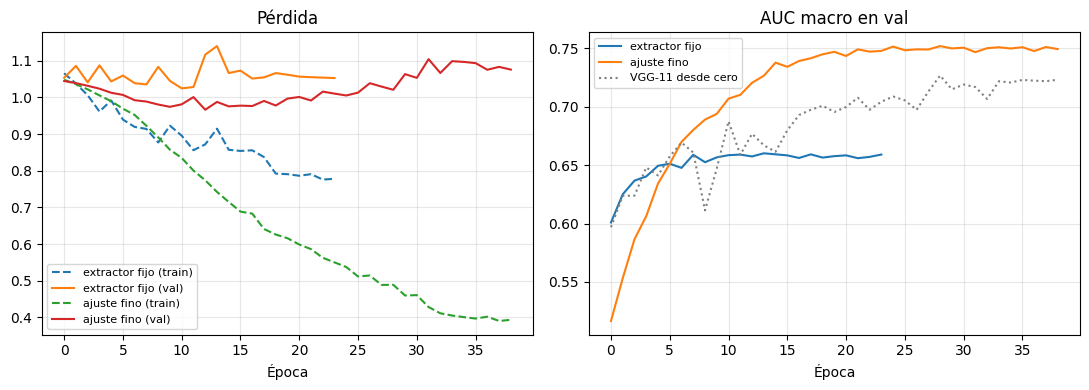


Modelo                       Mejor AUC val   Parámetros entrenados
VGG-11 (BN) desde cero               0.727              13,433,868
ResNet-50 · extractor fijo           0.660                  24,588
ResNet-50 · ajuste fino              0.752              23,532,620

AUC por hallazgo:
                  VGG-11  R50 extractor fijo  R50 ajuste fino
ACL                0.729               0.707            0.793
MCL                0.703               0.617            0.611
Medial Meniscus    0.662               0.618            0.659
Lateral Meniscus   0.621               0.513            0.637
Medial OA          0.835               0.695            0.843
Lateral OA         0.690               0.605            0.744
PF OA              0.732               0.592            0.730
Effusion           0.870               0.782            0.830
Synovitis          0.779               0.758            0.794
Baker's            0.632               0.643            0.739
Contusion          0.770      

In [17]:
# 11.5 — Transfer learning: ResNet-50 preentrenada en ImageNet (Lab Clase 5, Parte D)
import torchvision
from torchvision.models import ResNet50_Weights

CANALES_RGB = [2, 7, 12]                       # medial (−20 mm), centro (0), lateral (+20 mm) → R, G, B
ds_res, dl_res = crear_loaders(canales=CANALES_RGB, imagenet=True)

def build_feature_extractor(num_classes=12):
    """Estrategia 1 (Lab D.1): congelar toda la red y entrenar solo la nueva capa fc."""
    model = torchvision.models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(DEVICE)

def build_finetune_model(num_classes=12):
    """Estrategia 2 (Lab D.2): reemplazar fc y ajustar TODA la red."""
    model = torchvision.models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(DEVICE)

resultados_res = {}
for nombre, constructor, lr in [("extractor fijo", build_feature_extractor, 0.01),
                                ("ajuste fino",    build_finetune_model,    0.001)]:
    fijar_semilla()
    model = constructor()
    entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== ResNet-50 · {nombre} (lr {lr}) | entrenables: {entrenables:,} de {count_params(model):,} ===")
    model, hist, auc = train_model(model, dl_res, ds_res, epochs=40, lr=lr, weight_decay=0.0)
    torch.save(model.state_dict(), OUT / f"resnet50_{nombre.replace(' ', '_')}.pt")
    resultados_res[nombre] = (hist, auc, entrenables)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, (hist, auc, _) in resultados_res.items():
    axes[0].plot(hist["train_loss"], ls="--", label=f"{nombre} (train)"); axes[0].plot(hist["val_loss"], label=f"{nombre} (val)")
    axes[1].plot(hist["val_auc"], label=nombre)
axes[1].plot(hist_vgg11["val_auc"], c="gray", ls=":", label="VGG-11 desde cero")
axes[0].set_title("Pérdida"); axes[1].set_title("AUC macro en val")
for a in axes: a.set_xlabel("Época"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n{'Modelo':<28}{'Mejor AUC val':>14}{'Parámetros entrenados':>24}")
print(f"{'VGG-11 (BN) desde cero':<28}{auc_vgg11.mean():14.3f}{count_params(vgg11):24,}")
for nombre, (hist, auc, entrenables) in resultados_res.items():
    print(f"{'ResNet-50 · ' + nombre:<28}{auc.mean():14.3f}{entrenables:24,}")
print("\nAUC por hallazgo:")
print(pd.DataFrame({"VGG-11": auc_vgg11, **{f"R50 {n}": r[1] for n, r in resultados_res.items()}}).round(3).to_string())


### Interpretación — ResNet-50 (ImageNet): extractor fijo vs ajuste fino

| Modelo | Mejor AUC macro val | Parámetros entrenados |
|---|---|---|
| VGG-11 (BN) desde cero (15 cortes) | 0.727 | 13.4 M |
| ResNet-50 · extractor fijo (3 cortes) | 0.660 | 25 mil (solo `fc`) |
| **ResNet-50 · ajuste fino (3 cortes)** | **0.752** | 23.5 M |

**Extractor fijo (0.660):** se estanca en ~7 épocas. Las características de ImageNet (perros, autos, texturas de fotos)
**no bastan** para la RM si no se adaptan → coincide con la **matriz de decisión de la clase**: dataset **pequeño y muy
distinto** de ImageNet → hay que hacer ajuste fino.

**Ajuste fino (0.752): el mejor.** Los pesos de ImageNet son un **buen punto de partida** (bordes y texturas genéricos)
y, al adaptarlos, supera a la VGG desde cero aun viendo solo **3 cortes** en vez de 15.

⚠️ **Sobreajuste en la pérdida, no en el AUC:** la pérdida de train cae a 0.39 mientras la de val **sube** (0.98 → 1.08)
y el AUC de val se mantiene en ~0.75. La red sigue **ordenando** bien a los pacientes (AUC), pero sus probabilidades se
vuelven **demasiado seguras** (mala calibración) → importará al elegir el umbral para precision/recall/F1.

**Por hallazgo:**
- El ajuste fino gana claramente en **ACL (0.79), Contusion (0.85), Fracture (0.80), Baker's (0.74) y Lateral OA (0.74)**.
- La VGG gana en **MCL (0.70 frente a 0.61)** y **Effusion (0.87 frente a 0.83)**. La explicación es anatómica: la ResNet ve
  solo los cortes a −20, 0 y +20 mm, y el **LCM está en el borde medial** (~−40 mm), más lejos todavía que los ±28 mm
  de la VGG; el derrame se reparte por muchos cortes y la VGG ve los 15.
- **Dos modelos complementarios:** profundidad preentrenada (ResNet) frente a cobertura de cortes (VGG).

La diferencia entre la VGG y la ResNet en val (0.727 frente a 0.752) es pequeña para un val de 120 estudios → solo
el **test con intervalos de confianza** dirá si es real.


VGG-11 desde cero    | AUC macro test = 0.676  [IC 95 %: 0.604 – 0.748]
R50 extractor fijo   | AUC macro test = 0.690  [IC 95 %: 0.631 – 0.743]
R50 ajuste fino      | AUC macro test = 0.779  [IC 95 %: 0.732 – 0.827]

AUC por hallazgo en el test (IC 95 %):
                 VGG-11 desde cero R50 extractor fijo   R50 ajuste fino
ACL               0.72 [0.57–0.83]   0.76 [0.62–0.88]  0.83 [0.71–0.93]
MCL               0.57 [0.36–0.78]   0.70 [0.46–0.90]  0.69 [0.46–0.87]
Medial Meniscus   0.62 [0.48–0.76]   0.62 [0.46–0.77]  0.74 [0.61–0.87]
Lateral Meniscus  0.72 [0.57–0.85]   0.65 [0.50–0.79]  0.68 [0.53–0.81]
Medial OA         0.78 [0.60–0.92]   0.72 [0.56–0.88]  0.91 [0.82–0.98]
Lateral OA        0.55 [0.36–0.73]   0.68 [0.47–0.84]  0.75 [0.55–0.92]
PF OA             0.69 [0.54–0.82]   0.74 [0.59–0.87]  0.79 [0.65–0.92]
Effusion          0.82 [0.69–0.93]   0.78 [0.65–0.89]  0.89 [0.79–0.96]
Synovitis         0.73 [0.58–0.86]   0.62 [0.47–0.75]  0.73 [0.59–0.85]
Baker's           0.68 [

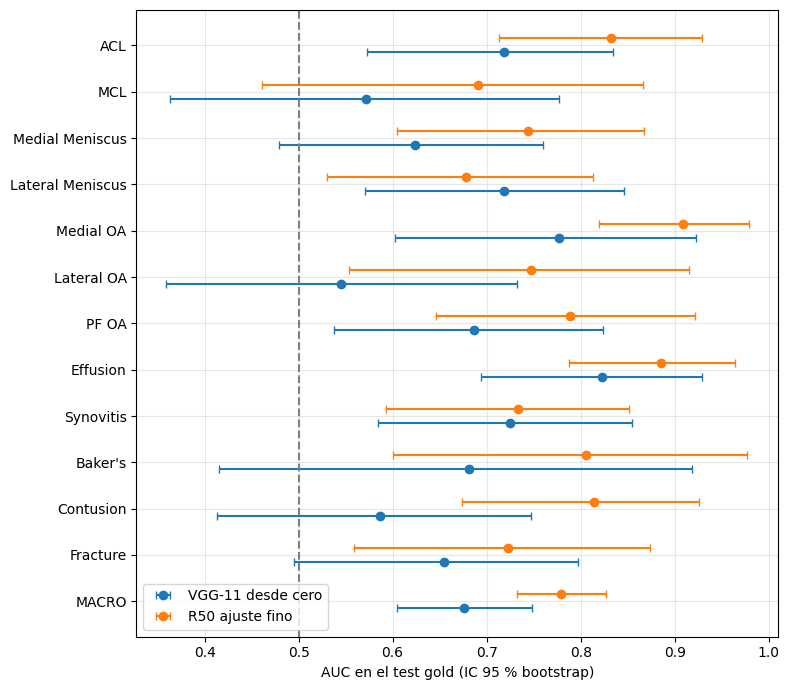

In [18]:
# 12.1 — Evaluación en el test (56 gold): AUC macro y por hallazgo con IC 95 % por bootstrap
@torch.no_grad()
def predecir(model, loader):
    model.eval()
    P, Y = [], []
    for inputs, labels in loader:
        P.append(torch.sigmoid(model(inputs.to(DEVICE))).cpu())
        Y.append(labels)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def bootstrap_auc(P, Y, n=1000, semilla=42):
    """Remuestrea los 56 estudios con reemplazo n veces y toma los percentiles 2.5 y 97.5 del AUC."""
    rng = np.random.default_rng(semilla)
    puntual = auc_por_etiqueta(P, Y)
    B = pd.DataFrame([auc_por_etiqueta(P[idx], Y[idx])
                      for idx in (rng.integers(0, len(Y), len(Y)) for _ in range(n))])
    tabla = pd.DataFrame({"AUC": puntual, "IC_inf": B.quantile(0.025), "IC_sup": B.quantile(0.975)})
    macro = B.mean(axis=1)
    tabla.loc["MACRO"] = [puntual.mean(), macro.quantile(0.025), macro.quantile(0.975)]
    return tabla

# Cargar los mejores pesos guardados (por si la sesión se reinició)
modelos = {
    "VGG-11 desde cero":   (VGG('A'),                   "vgg11_base.pt",                  dl_vgg),
    "R50 extractor fijo":  (build_feature_extractor(),  "resnet50_extractor_fijo.pt",     dl_res),
    "R50 ajuste fino":     (build_finetune_model(),     "resnet50_ajuste_fino.pt",        dl_res),
}
eval_test, pred_test = {}, {}
for nombre, (m, archivo, loaders) in modelos.items():
    m.load_state_dict(torch.load(OUT / archivo, map_location=DEVICE)); m.to(DEVICE)
    P, Y = predecir(m, loaders["test"])
    pred_test[nombre] = (P, Y)
    eval_test[nombre] = bootstrap_auc(P, Y)
    t = eval_test[nombre].loc["MACRO"]
    print(f"{nombre:<20} | AUC macro test = {t.AUC:.3f}  [IC 95 %: {t.IC_inf:.3f} – {t.IC_sup:.3f}]")

print("\nAUC por hallazgo en el test (IC 95 %):")
tab = pd.concat({n: e.apply(lambda r: f"{r.AUC:.2f} [{r.IC_inf:.2f}–{r.IC_sup:.2f}]", axis=1)
                 for n, e in eval_test.items()}, axis=1)
print(tab.to_string())

# Gráfico de intervalos (forest plot) de los dos modelos principales
fig, ax = plt.subplots(figsize=(8, 7))
for k, (nombre, color) in enumerate([("VGG-11 desde cero", "tab:blue"), ("R50 ajuste fino", "tab:orange")]):
    e = eval_test[nombre].iloc[::-1]
    yy = np.arange(len(e)) + (k - 0.5) * 0.3
    ax.errorbar(e.AUC, yy, xerr=[e.AUC - e.IC_inf, e.IC_sup - e.AUC], fmt="o", color=color, capsize=3, label=nombre)
ax.set_yticks(np.arange(len(e))); ax.set_yticklabels(e.index)
ax.axvline(0.5, ls="--", c="gray"); ax.set_xlabel("AUC en el test gold (IC 95 % bootstrap)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Interpretación  — Evaluación en el test (56 gold, etiquetas limpias)

| Modelo | AUC macro val (débil) | **AUC macro test (gold)** | IC 95 % |
|---|---|---|---|
| VGG-11 (BN) desde cero | 0.727 | 0.676 | 0.604 – 0.748 |
| ResNet-50 · extractor fijo | 0.660 | 0.690 | 0.631 – 0.743 |
| **ResNet-50 · ajuste fino** | 0.752 | **0.779** | **0.732 – 0.827** |

**El mejor modelo es la ResNet-50 con ajuste fino: AUC macro 0.78 en el test gold.**
- **Sube** de val (0.75) a test (0.78): en val se mide contra etiquetas débiles con ruido y en test contra etiquetas
  gold → el modelo aprendió de la **imagen** algo mejor que el ruido del texto (el objetivo del aprendizaje débilmente
  supervisado).
- La **VGG desde cero baja** de 0.73 a 0.68: sin preentrenamiento, con 480 estudios, parece haber aprendido parte de las
  "manías" de las etiquetas débiles, que no se sostienen frente al gold. El preentrenamiento en ImageNet da
  características más **generalizables**.
- Los IC de la VGG y la ResNet casi no se solapan (0.748 frente a 0.732) → la diferencia parece real (se confirma con un
  bootstrap pareado en el 12.2).

**Por hallazgo (ResNet-50, ajuste fino):**
- **Muy bien (≥ 0.80):** Medial OA 0.91, Effusion 0.89, ACL 0.83, Contusion 0.81, Baker's 0.81.
- **Moderado:** PF OA 0.79, Lateral OA 0.75, Medial Meniscus 0.74, Synovitis 0.73, Fracture 0.72.
- **Débil o incierto:** MCL 0.69 [0.46–0.87] y Lateral Meniscus 0.68 → el IC del LCM **incluye 0.5** (con 9 positivos en
  el test no se puede afirmar que lo detecte). Además, el LCM está fuera de los cortes que ve el modelo.

**Relación con la calidad de las etiquetas débiles (Paso 8):**
- **ACL y Baker's**, donde el extractor coincidía muy bien con el gold (κ hasta 0.92), salen bien.
- **Synovitis** (0.73) es moderado: en el Paso 8 vimos que el gold marca sinovitis que **los reportes no mencionan**
  (sensibilidad del extractor 0.44) → el modelo aprendió con etiquetas que subestiman la sinovitis.
- **Effusion** sale muy bien (0.89) **a pesar de** que su etiqueta débil era la más ruidosa (κ 0.31): el derrame es muy
  visible en una secuencia FS y la red lo aprende igual → **la red puede ser más robusta que sus etiquetas**.

**VGG-11:** Lateral OA (0.55), MCL (0.57) y Contusion (0.59) tienen IC que **incluyen 0.5** → no distinguibles del azar.


In [19]:
#  — Bootstrap PAREADO: diferencia de AUC macro entre dos modelos sobre los mismos pacientes
def bootstrap_diferencia(nombre_a, nombre_b, n=1000, semilla=42):
    (Pa, Y), (Pb, _) = pred_test[nombre_a], pred_test[nombre_b]
    rng = np.random.default_rng(semilla)
    dif = []
    for _ in range(n):
        idx = rng.integers(0, len(Y), len(Y))                       # los MISMOS pacientes para ambos
        dif.append(auc_por_etiqueta(Pa[idx], Y[idx]).mean() - auc_por_etiqueta(Pb[idx], Y[idx]).mean())
    dif = np.array(dif)
    obs = auc_por_etiqueta(Pa, Y).mean() - auc_por_etiqueta(Pb, Y).mean()
    print(f"{nombre_a} − {nombre_b}: ΔAUC macro = {obs:+.3f}  [IC 95 %: {np.quantile(dif, 0.025):+.3f} – "
          f"{np.quantile(dif, 0.975):+.3f}] | sorteos con Δ ≤ 0: {(dif <= 0).mean():.1%}")

bootstrap_diferencia("R50 ajuste fino", "VGG-11 desde cero")
bootstrap_diferencia("R50 ajuste fino", "R50 extractor fijo")
bootstrap_diferencia("R50 extractor fijo", "VGG-11 desde cero")


R50 ajuste fino − VGG-11 desde cero: ΔAUC macro = +0.103  [IC 95 %: +0.034 – +0.182] | sorteos con Δ ≤ 0: 0.2%
R50 ajuste fino − R50 extractor fijo: ΔAUC macro = +0.089  [IC 95 %: +0.043 – +0.141] | sorteos con Δ ≤ 0: 0.0%
R50 extractor fijo − VGG-11 desde cero: ΔAUC macro = +0.014  [IC 95 %: -0.068 – +0.095] | sorteos con Δ ≤ 0: 37.1%


### Interpretación — Comparación pareada de modelos (bootstrap pareado, 1000 sorteos, test gold)

| Comparación | ΔAUC macro | IC 95 % | Sorteos con Δ ≤ 0 | ¿Diferencia real? |
|---|---|---|---|---|
| R50 ajuste fino − VGG-11 desde cero | **+0.103** | +0.034 – +0.182 | 0.2 % | ✅ Sí |
| R50 ajuste fino − R50 extractor fijo | **+0.089** | +0.043 – +0.141 | 0.0 % | ✅ Sí |
| R50 extractor fijo − VGG-11 desde cero | +0.014 | −0.068 – +0.095 | 37 % | ❌ No |

- **El ajuste fino de ResNet-50 es significativamente mejor que los otros dos modelos**: el IC de la diferencia está
  entero por encima de 0 (equivale a p ≈ 0.002 y p < 0.001).
- **Extractor fijo y VGG desde cero son equivalentes**: ni las características de ImageNet congeladas ni una red
  entrenada desde cero con 480 estudios alcanzan; lo que marca la diferencia es **combinar preentrenamiento + adaptación**.
- El bootstrap **pareado** es más potente que comparar IC por separado: usa los mismos pacientes para ambos modelos,
  así que la variación "por qué pacientes tocaron" se cancela y solo queda la diferencia entre modelos.
- ✅ **Modelo final: ResNet-50 (ImageNet) con ajuste fino → AUC macro 0.779 [0.732 – 0.827] en los 56 gold.**


In [20]:
# — Umbral por hallazgo elegido en VAL (máximo F1) y aplicado al TEST
from sklearn.metrics import precision_recall_fscore_support, f1_score

m_final = modelos["R50 ajuste fino"][0]
Pv, Yv = predecir(m_final, dl_res["val"])          # val: etiquetas débiles (se excluyen los −1)
Pt, Yt = pred_test["R50 ajuste fino"]              # test: gold
CANDIDATOS = np.arange(0.05, 0.96, 0.01)

filas = []
for j, e in enumerate(LABELS):
    m = Yv[:, j] != -1
    f1_val = [f1_score(Yv[m, j], Pv[m, j] >= u, zero_division=0) for u in CANDIDATOS]
    u = CANDIDATOS[int(np.argmax(f1_val))]
    p, r, f, _ = precision_recall_fscore_support(Yt[:, j], Pt[:, j] >= u, average="binary", zero_division=0)
    _, _, f05, _ = precision_recall_fscore_support(Yt[:, j], Pt[:, j] >= 0.5, average="binary", zero_division=0)
    filas.append({"hallazgo": e, "umbral (val)": u, "F1 val": max(f1_val),
                  "precision": p, "recall": r, "F1": f, "F1 con 0.5": f05, "pos. test": int(Yt[:, j].sum())})

tabla_umbral = pd.DataFrame(filas).set_index("hallazgo")
tabla_umbral.loc["MACRO"] = tabla_umbral.drop(columns="pos. test").mean()
print(tabla_umbral.round(2).to_string())


                  umbral (val)  F1 val  precision  recall    F1  F1 con 0.5  pos. test
hallazgo                                                                              
ACL                       0.48    0.64       0.76    0.70  0.73        0.70       23.0
MCL                       0.33    0.38       0.23    0.56  0.32        0.38        9.0
Medial Meniscus           0.37    0.62       0.53    0.75  0.62        0.67       24.0
Lateral Meniscus          0.38    0.42       0.52    0.52  0.52        0.44       23.0
Medial OA                 0.31    0.66       0.67    0.93  0.78        0.69       15.0
Lateral OA                0.38    0.51       0.43    0.55  0.48        0.45       11.0
PF OA                     0.42    0.57       0.70    0.70  0.70        0.57       20.0
Effusion                  0.31    0.86       0.70    0.97  0.81        0.84       34.0
Synovitis                 0.44    0.57       0.65    0.44  0.52        0.46       25.0
Baker's                   0.27    0.51     

### Interpretación — Umbral, precision, recall y F1 (ResNet-50 ajuste fino, test gold)

**Criterio del umbral:** uno por hallazgo, el que **maximiza el F1 en val** (etiquetas débiles, sin −1), aplicado al test
sin modificarlo. No se usa 0.5 porque el `pos_weight` desplaza las probabilidades y el mejor corte cambia por hallazgo.

**Resultado global:** F1 macro **0.60** con los umbrales de val frente a **0.58** con 0.5 → mejora **pequeña**.
En 4 hallazgos (MCL, Medial Meniscus, Effusion, Baker's) el corte de 0.5 habría funcionado mejor → los umbrales elegidos
en val **no transfieren perfectamente** al test, porque (1) val tiene etiquetas débiles, (2) solo 120 estudios y
(3) el test tiene casi el doble de prevalencia. Es la advertencia anotada desde el Paso 2.

**Por hallazgo:**
- **Buen desempeño:** Effusion F1 0.81 (recall 0.97), Medial OA 0.78 (recall 0.93), ACL 0.73 (precision 0.76 /
  recall 0.70), PF OA 0.70.
- **Synovitis: recall 0.44, el mismo valor que la sensibilidad del extractor frente al gold en el Paso 8 (0.44)** →
  el modelo **heredó el sesgo de sus etiquetas**: aprendió la sinovitis "como la escriben los reportes", que la
  subestiman respecto al gold. Es un ejemplo directo de cómo el ruido de la supervisión débil pasa al modelo.
- **Contusion y Fracture:** umbrales altos (0.73 y 0.69) → modelo **conservador**: precision alta (0.82 / 0.69),
  recall bajo (0.50 / 0.53).
- **MCL (F1 0.32, precision 0.23)** y **Baker's (0.46)**: los más débiles. El LCM y el quiste de Baker están en la
  periferia medial/posterior, fuera de los cortes que ve el modelo; el LCM además tiene solo 9 positivos en el test.

**Advertencia sobre la precision:** el test está enriquecido (p. ej. ACL 41 % frente a ~14 % en la población). Como la
precision depende de la prevalencia, **en la práctica clínica sería menor** que la mostrada aquí; recall y AUC no
dependen de ella.


In [21]:
# 13 — Ablación sobre el modelo final (ResNet-50 ajuste fino): política del −1 y profundidad del backbone
from torchvision.models import ResNet18_Weights

def build_finetune_resnet18(num_classes=12):
    model = torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(DEVICE)

experimentos = [   # (nombre, constructor, política del −1)
    ("R50 · −1 como 0",   build_finetune_model,    "cero"),
    ("R50 · −1 como 1",   build_finetune_model,    "uno"),
    ("R18 · −1 ignorado", build_finetune_resnet18, "ignorar"),
]

auc_val_abl = {"R50 · −1 ignorado (base)": auc_por_etiqueta(Pv, Yv).mean()}
pred_test["R50 · −1 ignorado (base)"] = pred_test["R50 ajuste fino"]

for nombre, constructor, pol in experimentos:
    print(f"\n=== {nombre} ===")
    fijar_semilla()
    m, hist, auc_val = train_model(constructor(), dl_res, ds_res, epochs=50, lr=0.001, weight_decay=0.0, politica=pol)
    torch.save(m.state_dict(), OUT / f"abl_{nombre.replace(' ', '_').replace('·', '').replace('−', 'm')}.pt")
    auc_val_abl[nombre] = auc_val.mean()
    pred_test[nombre] = predecir(m, dl_res["test"])

print("\n================ RESUMEN DE LA ABLACIÓN ================")
for nombre in auc_val_abl:
    t = bootstrap_auc(*pred_test[nombre]).loc["MACRO"]
    print(f"{nombre:<26} | AUC val {auc_val_abl[nombre]:.3f} | AUC test {t.AUC:.3f} [{t.IC_inf:.3f} – {t.IC_sup:.3f}]")
print()
for nombre, _, _ in experimentos:
    bootstrap_diferencia(nombre, "R50 · −1 ignorado (base)")

print("\nAUC por hallazgo en el test:")
print(pd.DataFrame({n: auc_por_etiqueta(*pred_test[n]) for n in auc_val_abl}).round(2).to_string())



=== R50 · −1 como 0 ===
Época  1/50 | pérdida train 1.076 | pérdida val 1.071 | AUC val 0.520 ★ | lr 1e-03
Época  2/50 | pérdida train 1.065 | pérdida val 1.065 | AUC val 0.561 ★ | lr 1e-03
Época  3/50 | pérdida train 1.051 | pérdida val 1.059 | AUC val 0.590 ★ | lr 1e-03
Época  4/50 | pérdida train 1.037 | pérdida val 1.051 | AUC val 0.611 ★ | lr 1e-03
Época  5/50 | pérdida train 1.022 | pérdida val 1.044 | AUC val 0.629 ★ | lr 1e-03
Época  6/50 | pérdida train 1.003 | pérdida val 1.041 | AUC val 0.644 ★ | lr 1e-03
Época  7/50 | pérdida train 0.986 | pérdida val 1.024 | AUC val 0.666 ★ | lr 1e-03
Época  8/50 | pérdida train 0.960 | pérdida val 1.020 | AUC val 0.675 ★ | lr 1e-03
Época  9/50 | pérdida train 0.929 | pérdida val 1.015 | AUC val 0.688 ★ | lr 1e-03
Época 10/50 | pérdida train 0.899 | pérdida val 1.009 | AUC val 0.696 ★ | lr 1e-03
Época 11/50 | pérdida train 0.878 | pérdida val 1.015 | AUC val 0.706 ★ | lr 1e-03
Época 12/50 | pérdida train 0.843 | pérdida val 1.026 | AUC va

100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


Época  1/50 | pérdida train 1.065 | pérdida val 1.048 | AUC val 0.540 ★ | lr 1e-03
Época  2/50 | pérdida train 1.034 | pérdida val 1.040 | AUC val 0.562 ★ | lr 1e-03
Época  3/50 | pérdida train 0.999 | pérdida val 1.024 | AUC val 0.588 ★ | lr 1e-03
Época  4/50 | pérdida train 0.972 | pérdida val 1.014 | AUC val 0.612 ★ | lr 1e-03
Época  5/50 | pérdida train 0.947 | pérdida val 1.004 | AUC val 0.632 ★ | lr 1e-03
Época  6/50 | pérdida train 0.922 | pérdida val 0.996 | AUC val 0.651 ★ | lr 1e-03
Época  7/50 | pérdida train 0.894 | pérdida val 0.982 | AUC val 0.666 ★ | lr 1e-03
Época  8/50 | pérdida train 0.864 | pérdida val 0.977 | AUC val 0.680 ★ | lr 1e-03
Época  9/50 | pérdida train 0.841 | pérdida val 0.974 | AUC val 0.686 ★ | lr 1e-03
Época 10/50 | pérdida train 0.808 | pérdida val 0.972 | AUC val 0.698 ★ | lr 1e-03
Época 11/50 | pérdida train 0.797 | pérdida val 0.955 | AUC val 0.703 ★ | lr 1e-03
Época 12/50 | pérdida train 0.750 | pérdida val 0.975 | AUC val 0.713 ★ | lr 1e-03
Époc

### Interpretación 13 — Ablación (sobre ResNet-50 ajuste fino; test gold, bootstrap pareado)

| Variante | AUC val | AUC test [IC 95 %] | ΔAUC vs base [IC 95 %] |
|---|---|---|---|
| **Base: R50, −1 ignorado** | 0.752 | **0.779** [0.732 – 0.827] | — |
| R50, −1 como 0 | 0.751 | 0.771 [0.724 – 0.816] | −0.008 [−0.022 – +0.005] |
| R50, −1 como 1 | 0.760 | 0.773 [0.725 – 0.823] | −0.006 [−0.027 – +0.014] |
| R18, −1 ignorado | 0.757 | 0.768 [0.720 – 0.815] | −0.011 [−0.043 – +0.022] |

**Factor 1 — Manejo de etiquetas ruidosas (política del −1):** las tres políticas dan resultados **equivalentes**
(diferencias ≤ 0.01, todos los IC cruzan 0). Ignorar el −1 queda numéricamente primero, pero sin diferencia
significativa. Con ~20 % de −1 solo en algunas etiquetas, el modelo es **robusto** a cómo se traten.

**Contraste con las hipótesis previas (escritas antes de correr):**
- ❌ "−1 como 1 ayudará a PF OA y Contusion" → **refutada**: PF OA 0.79 → 0.74 y Contusion 0.81 → 0.73.
  Posible explicación: los −1 de contusión son "edema óseo sin contexto", que incluye edema **reactivo** (por artrosis o
  menisco); al contarlos como contusión, el modelo aprende "cualquier edema = contusión" y pierde especificidad.
  Coincidir mejor con la *definición* del gold en el texto no garantiza que el modelo aprenda mejor de la *imagen*.
- ✅ "−1 como 1 perjudicará a Effusion" → coherente, pero mínimo (0.89 → 0.87).
- ❌ "−1 como 0 perjudicará a PF OA y Contusion" → sin efecto (0.77 / 0.81).
- ⚠️ Las diferencias por hallazgo (±0.05) están **dentro del ruido** (IC por hallazgo de ±0.10): son tendencias, no
  conclusiones.

**Factor 2 — Profundidad del backbone:** ResNet-18 (11 M parámetros, 1.6 min de entrenamiento) rinde **igual** que
ResNet-50 (23.5 M): −0.011, no significativo → con 480 estudios, **más capacidad no aporta**; el límite está en la
cantidad y calidad de los datos, no en la red.

**Factor 3 (11.5) — Estrategia de transfer:** ajuste fino frente a extractor fijo = **+0.089, significativo**:
es el **único factor que importa** de los estudiados.

**Conclusión de la ablación:** lo decisivo es **adaptar** una red preentrenada al dominio de la RM. La política del −1
y la profundidad tienen efectos menores que la incertidumbre de evaluar con 56 estudios gold (que no permite detectar
diferencias menores a ~0.03).


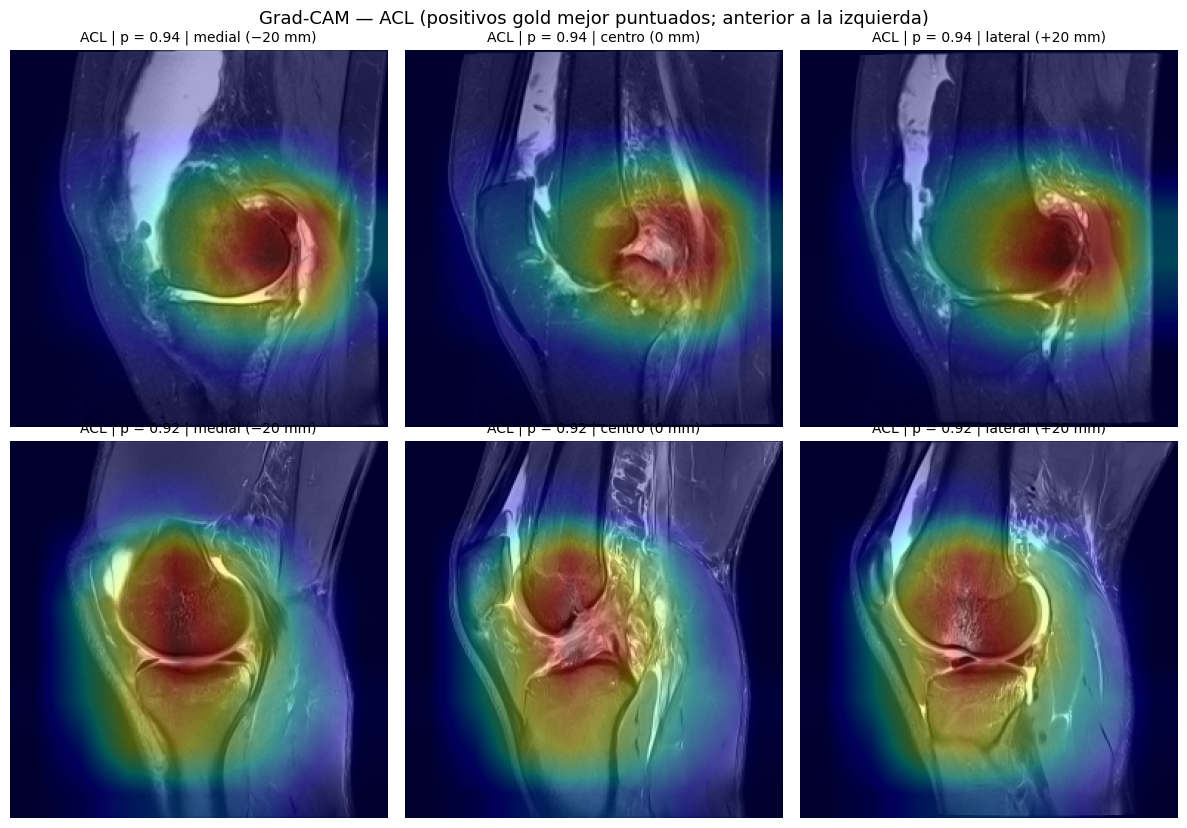

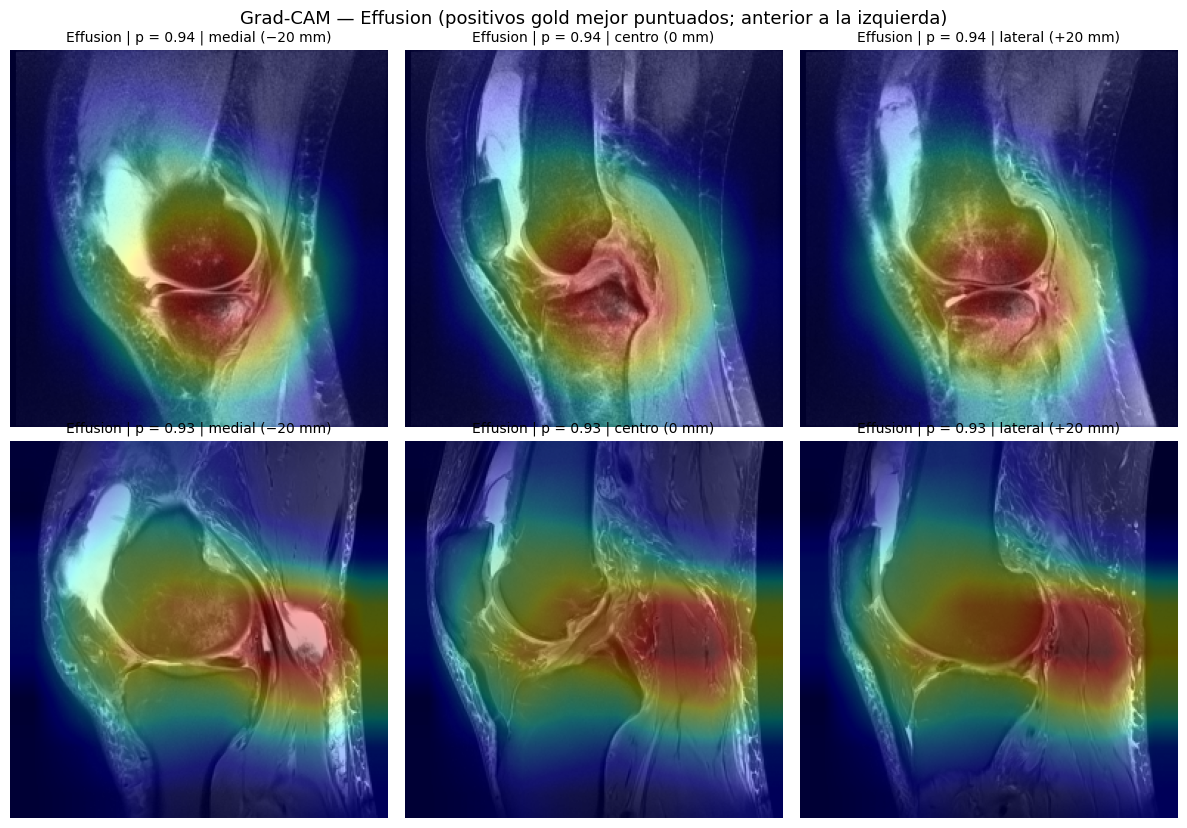

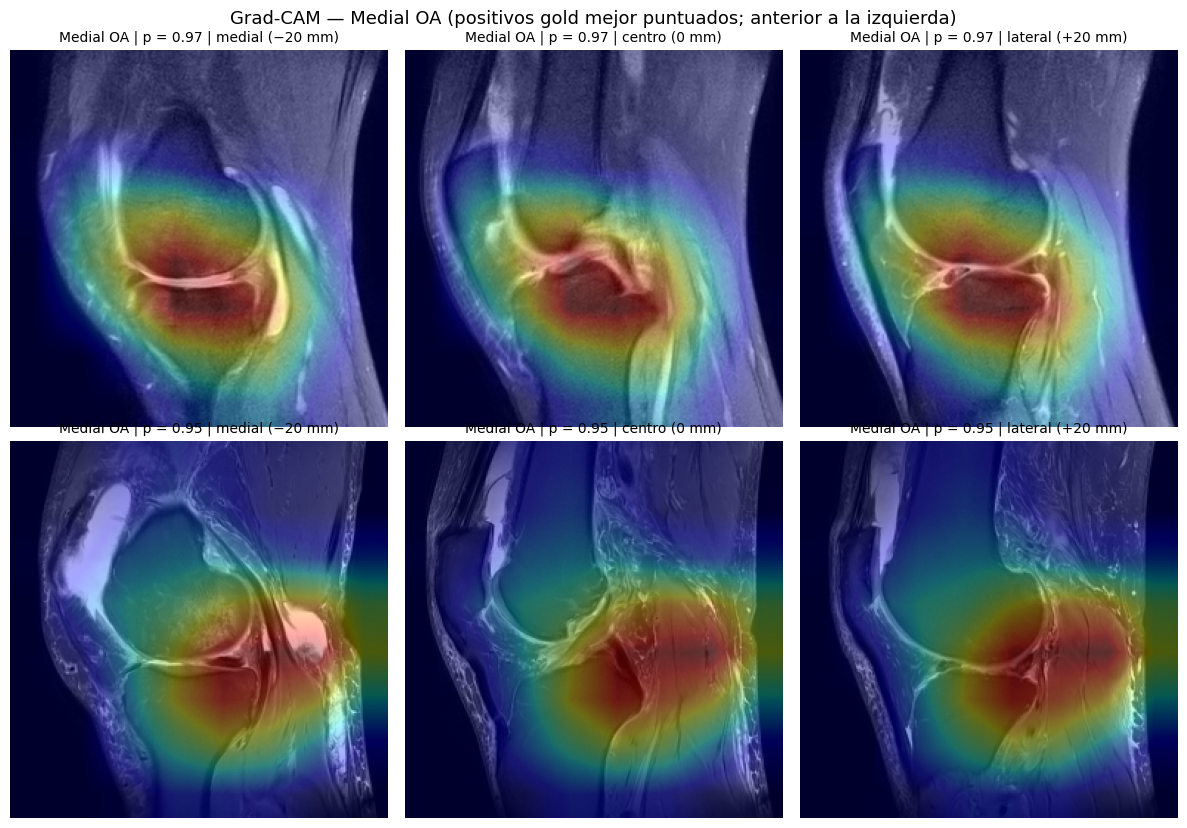

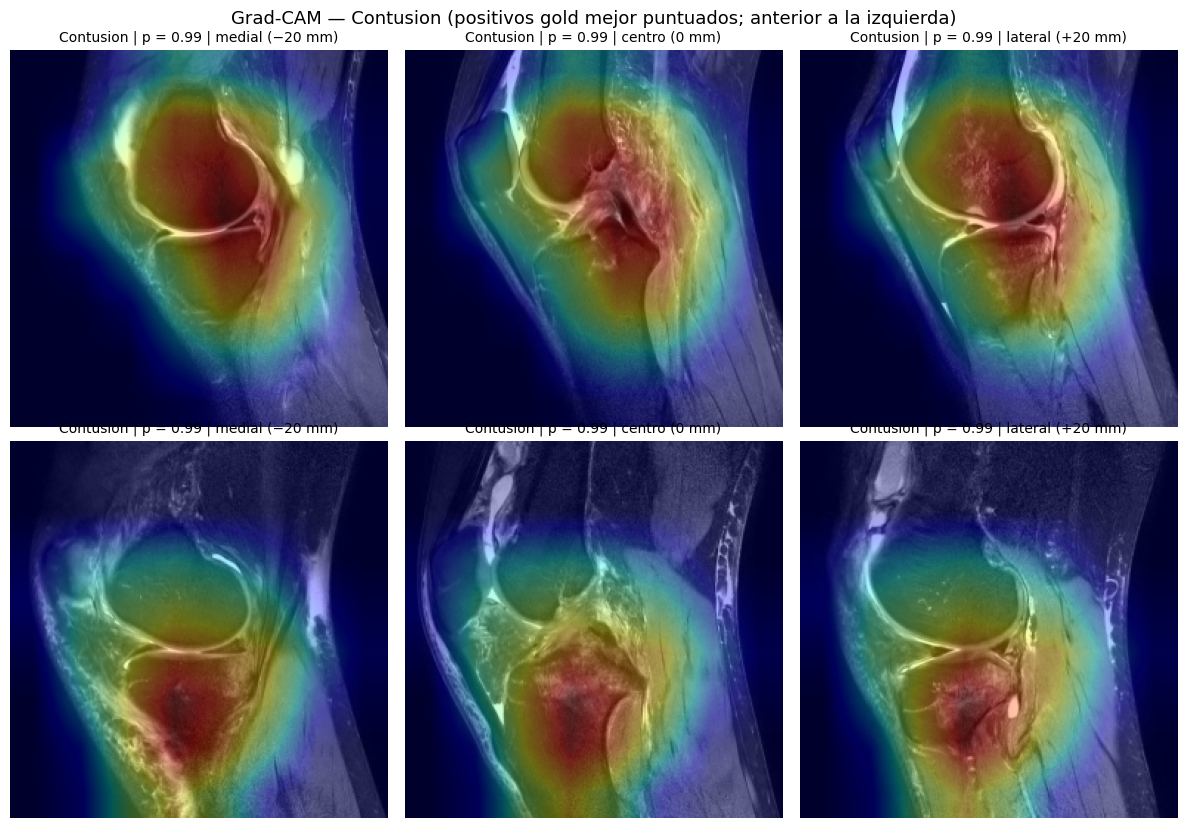

In [22]:
# 14 — Grad-CAM (Selvaraju et al., 2017) sobre la ResNet-50 con ajuste fino
class GradCAM:
    def __init__(self, model, capa):
        self.model, self.act, self.grad = model, None, None
        def guardar(modulo, entrada, salida):
            self.act = salida                                            # mapas de activación [1, 2048, 8, 8]
            salida.register_hook(lambda g: setattr(self, "grad", g))     # su gradiente, en el backward
        capa.register_forward_hook(guardar)

    def __call__(self, x, k):
        self.model.eval(); self.model.zero_grad()
        logit = self.model(x)[0, k]
        logit.backward()
        pesos = self.grad.mean(dim=(2, 3), keepdim=True)                 # importancia de cada mapa
        cam = F.relu((pesos * self.act).sum(dim=1, keepdim=True))        # suma ponderada, solo lo positivo
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(logit).item()

import torch.nn.functional as F
gradcam = GradCAM(m_final, m_final.layer4[-1])
uids_test = ds_res["test"].uids
NOMBRES_RGB = ["medial (−20 mm)", "centro (0 mm)", "lateral (+20 mm)"]

def mostrar_gradcam(hallazgo, n_casos=2):
    k = LABELS.index(hallazgo)
    positivos = np.where(Yt[:, k] == 1)[0]
    casos = positivos[np.argsort(-Pt[positivos, k])][:n_casos]           # positivos gold con mayor probabilidad
    fig, ax = plt.subplots(n_casos, 3, figsize=(12, 4.2 * n_casos))
    for r, i in enumerate(casos):
        x, _ = ds_res["test"][i]
        cam, prob = gradcam(x.unsqueeze(0).to(DEVICE), k)
        crudo = VOL[uids_test[i]][CANALES_RGB].astype(np.float32)        # cortes sin normalizar, para mostrar
        for c in range(3):
            ax[r, c].imshow(crudo[c], cmap="gray", vmin=0, vmax=1)
            ax[r, c].imshow(cam, cmap="jet", alpha=0.35)
            ax[r, c].set_title(f"{hallazgo} | p = {prob:.2f} | {NOMBRES_RGB[c]}", fontsize=10)
            ax[r, c].axis("off")
    plt.suptitle(f"Grad-CAM — {hallazgo} (positivos gold mejor puntuados; anterior a la izquierda)", fontsize=13)
    plt.tight_layout(); plt.show()

for hallazgo in ["ACL", "Effusion", "Medial OA", "Contusion"]:
    mostrar_gradcam(hallazgo)


### Interpretación 14 — Grad-CAM (ResNet-50 ajuste fino; 2 positivos gold con mayor probabilidad por hallazgo)

**Limitaciones del método, para leer los mapas con cuidado:**
- La última capa de la ResNet es de **8×8** → cada "celda" del mapa cubre ~32×32 píxeles (≈ 2 cm): Grad-CAM señala
  **regiones**, no estructuras finas como un ligamento de 1 cm de ancho.
- El mapa es **el mismo en los 3 cortes** (localiza en el plano sagital, no entre cortes).
- Se muestran los aciertos **más seguros** → casos fáciles; no representan los errores.

| Hallazgo | Dónde mira | ¿Plausible? |
|---|---|---|
| **Contusion** | Caso 1: **cóndilo femoral** con médula moteada brillante (edema óseo), sobre todo en el corte lateral. Caso 2: **tibia proximal** con edema en los cortes medial y central | ✅ **Sí**: el calor cae justo sobre el hueso con edema |
| **Medial OA** | Caso 1: **interlínea femorotibial**, máxima en el corte medial. Caso 2: región **posterior** de la articulación (cuerno posterior / zona poplítea) | ✅ Caso 1 muy plausible; ⚠️ caso 2 parcial: incluye una colección posterior |
| **ACL** | Centro de la rodilla: **escotadura intercondílea** (donde se ve la señal desorganizada en el corte central) y el **cóndilo femoral** | ⚠️ **Parcial**: mira la zona correcta, pero también el hueso; la rotura del LCA suele acompañarse de contusiones en el cóndilo femoral lateral y la tibia ("patrón de pivote") → el modelo podría usar la **contusión asociada** como pista |
| **Effusion** | Caso 1: centro de la articulación femorotibial. Caso 2: región **posterior/poplítea** con una colección brillante | ⚠️ **Poco plausible**: **no** mira el **receso suprapatelar**, donde el derrame es más evidente (líquido blanco arriba y delante, visible en las imágenes). Mira otras zonas con líquido o hallazgos asociados (¿quiste de Baker?) |

**Interpretación general:** para hallazgos **localizados y propios del hueso** (contusión, artrosis medial) el modelo
mira donde debe. Para **ACL y Effusion** usa en parte **evidencia indirecta**: hallazgos que en el dataset aparecen
junto con ellos (co-ocurrencias del Paso 2: ACL–Contusion–Effusion; Effusion–Baker's). Es la limitación típica de la
**supervisión débil a nivel de estudio**: la red aprende **cualquier** señal correlacionada con la etiqueta, no
necesariamente la estructura que la define.


In [23]:
# 14b — Etiquetas GOLD de los casos mostrados en el Grad-CAM (¿hallazgos asociados?)
filas = []
for hallazgo in ["ACL", "Effusion", "Medial OA", "Contusion"]:
    k = LABELS.index(hallazgo)
    positivos = np.where(Yt[:, k] == 1)[0]
    for r, i in enumerate(positivos[np.argsort(-Pt[positivos, k])][:2]):
        otros = [e for j, e in enumerate(LABELS) if Yt[i, j] == 1 and e != hallazgo]
        filas.append({"Grad-CAM de": hallazgo, "caso": r + 1, "p": round(float(Pt[i, k]), 2),
                      "otros hallazgos gold": ", ".join(otros) if otros else "—"})
print(pd.DataFrame(filas).to_string(index=False))


Grad-CAM de  caso    p                                                                          otros hallazgos gold
        ACL     1 0.94 Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's
        ACL     2 0.92                                         MCL, Lateral Meniscus, Effusion, Synovitis, Contusion
   Effusion     1 0.94                        ACL, Medial Meniscus, Lateral Meniscus, Synovitis, Contusion, Fracture
   Effusion     2 0.93 Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Synovitis, Baker's, Fracture
  Medial OA     1 0.97                                                 Medial Meniscus, Effusion, Synovitis, Baker's
  Medial OA     2 0.95  Medial Meniscus, Lateral Meniscus, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Fracture
  Contusion     1 0.99                                                ACL, Medial Meniscus, PF OA, Effusion, Baker's
  Contusion     2 0.99                                          

### Interpretación 14b — Hallazgos gold asociados en los casos del Grad-CAM

| Grad-CAM de | Caso | Otros hallazgos gold | ¿Respalda la hipótesis? |
|---|---|---|---|
| ACL | 2 | **Contusion**, Effusion, MCL… | ✅ el calor sobre el hueso puede ser la contusión asociada |
| ACL | 1 | OA medial/lateral/PF, meniscos, Effusion, Baker's (sin contusión) | ⚠️ rodilla **degenerativa**: el calor en el cóndilo puede deberse a la artrosis |
| Effusion | 2 | **Baker's**, meniscos, OA… | ✅ la colección posterior es compatible con el quiste de Baker |
| Medial OA | 2 | **Baker's**, Effusion… | ✅ ídem: el calor posterior incluye el quiste |
| Contusion | 1 y 2 | **ACL + Effusion** en ambos | ✅ patrón de **pivote** (rotura de LCA + contusión + derrame) |

**Hallazgo clave:** los casos que el modelo puntúa con más seguridad son rodillas **con muchos hallazgos a la vez**
(5 a 8 de 12). En esas rodillas, las 12 salidas comparten la misma evidencia visual ("rodilla muy patológica"), y el
Grad-CAM de un hallazgo **no puede separarse** del de los demás.

**Conclusión para el informe:** el modelo aprende en parte una noción de **"gravedad general"** de la rodilla, además
de los hallazgos específicos. Es una consecuencia directa de: (1) supervisión **a nivel de estudio** (sin indicar
dónde está cada hallazgo), (2) fuertes **co-ocurrencias** clínicas (pivote: ACL–Contusion–Effusion; degeneración:
meniscos–OA–Baker's) y (3) una sola cabeza que comparte las mismas características para las 12 salidas. Para separar
los hallazgos harían falta anotaciones de localización (cajas o máscaras), que este dataset no tiene.


In [24]:
# 15 — Sesgos: AUC macro del modelo final por subgrupo (idioma del reporte, fabricante, contraste)
preds = {"val": (Pv, Yv), "test": (Pt, Yt)}
filas = []
for s in ["val", "test"]:
    P, Y = preds[s]
    df = indice[indice.split == s].reset_index(drop=True)          # mismo orden que el DataLoader (sin shuffle)
    df["idioma (en / otros)"] = np.where(df["idioma"] == "en", "en", "otros")
    for var in ["idioma (en / otros)", "idioma", "fabricante", "contraste"]:
        for grupo, idx in df.groupby(var).groups.items():
            idx = np.asarray(idx)
            if len(idx) < 8:                                       # grupos muy chicos: AUC sin sentido
                continue
            auc = auc_por_etiqueta(P[idx], Y[idx])
            filas.append({"split": s, "variable": var, "grupo": grupo, "n": len(idx),
                          "AUC macro": round(auc.mean(), 3), "etiquetas evaluables": int(auc.notna().sum())})

sesgos = pd.DataFrame(filas)
for var in ["idioma (en / otros)", "idioma", "fabricante", "contraste"]:
    print(f"\n=== {var} ===")
    print(sesgos[sesgos.variable == var].drop(columns="variable").to_string(index=False))



=== idioma (en / otros) ===
split grupo  n  AUC macro  etiquetas evaluables
  val    en 54      0.766                    12
  val otros 66      0.737                    12
 test    en 28      0.797                    12
 test otros 28      0.777                    12

=== idioma ===
split grupo  n  AUC macro  etiquetas evaluables
  val    bg  8      0.830                     7
  val    el  8      0.682                    10
  val    en 54      0.766                    12
  val    es 20      0.726                    12
  val    hr  9      0.724                     9
  val    tr 12      0.711                    11
 test    en 28      0.797                    12
 test    es 10      0.710                     9

=== fabricante ===
split   grupo  n  AUC macro  etiquetas evaluables
  val      GE 22      0.797                    12
  val PHILIPS 38      0.723                    12
  val SIEMENS 48      0.749                    12
  val TOSHIBA  9      0.644                    12
 test      GE

### Interpretación 15 — Desempeño del modelo final por subgrupo (AUC macro; val = débil, test = gold)

| Variable | Resultado |
|---|---|
| **Idioma: en vs otros** | en es mejor en **ambos** splits: val 0.766 vs 0.737; test 0.797 vs 0.777 (Δ ≈ 0.02–0.03) |
| **Idioma (detalle)** | **es** queda bajo en val (0.726) y en test (0.710); tr 0.71, hr 0.72, el 0.68 (n = 8), bg 0.83 (n = 8, solo 7 etiquetas evaluables) |
| **Fabricante** | GE ≈ 0.80 en val y test; Siemens 0.75 / 0.77; Philips 0.72 / 0.76; **Toshiba 0.64** (val, n = 9) |
| **Contraste** | T2 0.786 vs DP 0.746 (val): la T2 **no** sale peor pese a ser solo el 13 % del entrenamiento |

- **No hay brechas grandes (≥ 0.10)** salvo Toshiba, con solo 9 estudios.
- Hay un **patrón consistente**: el inglés queda por encima del resto en val **y** en test. Con grupos de 8–54 estudios
  la diferencia no es significativa, pero va en la dirección esperada: el inglés es el idioma más representado en
  train y aquel donde el extractor tuvo más acuerdo con el gold (0.85, Paso 8.2).
- El español queda bajo en ambos splits: incluye los reportes-plantilla más cortos ("Sin anomalías", Paso 3), que
  aportan menos información a la etiqueta débil.
- ⚠️ **El sesgo mayor no se puede medir aquí:** los centros **alemanes** quedaron casi todos **excluidos** (no adquieren
  sagital FS) → no sabemos cómo rinde el modelo en esa población.



### Discusión: sesgo geográfico y lingüístico

El conjunto de datos proviene de 16 centros con reportes en al menos 9 idiomas, y esta heterogeneidad introduce sesgos
en tres puntos del pipeline. **(1) Selección por protocolo.** Elegir la secuencia sagital sensible al líquido con
supresión grasa excluyó casi por completo a los centros alemanes, que adquieren la sagital sin supresión grasa
(solo el 6.5 % de sus estudios es elegible; 95 % de los excluidos son alemanes, incluidos 2 de los 58 gold). El modelo
nunca vio ni fue evaluado en esa población, por lo que su desempeño allí es desconocido. **(2) Etiquetas dependientes
del idioma y del estilo de reporte.** El extractor de reglas obtuvo un acuerdo con el gold de 0.85 en inglés frente a
0.67–0.82 en otros idiomas (con 2–10 gold por idioma, estimaciones inestables), y no pudo validarse en francés (0 gold).
Además, la prevalencia de etiquetas débiles varía con el estilo de cada centro más que con la clínica: los reportes
búlgaros casi nunca mencionan sinovitis (0 % frente a 17 % en inglés). Como la red aprende de esas etiquetas, hereda
su sesgo: el recall de sinovitis en el test (0.44) coincide con la sensibilidad del extractor frente al gold (0.44).
**(3) Desempeño por subgrupo.** El AUC macro del modelo final es algo mayor en estudios con reporte en inglés que en
el resto, tanto en validación (0.77 frente a 0.74) como en el test gold (0.80 frente a 0.78), y menor en español
(0.73 / 0.71); por fabricante varía entre 0.72 y 0.80 (Toshiba 0.64, n = 9). Ninguna diferencia es significativa con
grupos de 8–54 estudios, pero la dirección es consistente con la mayor representación del inglés y la mejor calidad
de sus etiquetas. **Implicaciones:** un despliegue en centros o idiomas poco representados requeriría validación local;
como mitigaciones se proponen estratificar el entrenamiento por centro e idioma, extender el extractor (o usar modelos
de lenguaje multilingües) a los idiomas con bajo acuerdo, y armonizar la intensidad entre fabricantes, e incluir la
sagital sin supresión grasa para no excluir poblaciones enteras por su protocolo de adquisición.
